# Comparison: LRA: Phase 2 DestinE data: thetao: Data Analysis

### Why this notebook matters

This notebook demonstrates domain-mean ocean-temperature Hovmoller diagnostics, comparing three coupled climate models against the EN4 objective ocean analysis.

**Purpose** - Evaluate ocean potential temperature (`thetao`) in the LRA Phase 2 models (IFS-FESOM, IFS-NEMO, ICON) against the EN4 objective analysis: domain-mean time-depth (Hovmoller) datasets, anomalies relative to January 1990, and a 4-panel model/observation comparison.

**Required input data** - Monthly `thetao` NetCDF files (r100) under `{LRA_ROOT}`; EN4.2.2 monthly analysis files (`{EN4_DIR}`); derived domain-mean datasets are read from and written to `{EVA_DIR}` (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - Domain-mean time-depth NetCDF files in `{EVA_DIR}`; Hovmoller anomaly figures for all three models and EN4 embedded below.

## Key techniques demonstrated

- xarray for NetCDF I/O
- Domain-mean Hovmoller (depth-time) diagnostics
- Multi-model vs EN4 comparison
- matplotlib multi-panel figures

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set these paths to your own data copies before running:
#
# LRA_ROOT        : Destination Earth LRA Phase 2 data root
#                   (subfolders: climatedt-o25.1/<MODEL>/historical-*/r100/monthly/)
# EVA_DIR         : working directory for derived NetCDF files
# EN4_DIR         : extracted EN4.2.2 monthly analysis files
# FESOM_DATA_ROOT : FESOM2 climatologies (only used in a side check)

LRA_ROOT        = "/path/to/DestinE/LRA_phase2"  # <-- EDIT before running
EVA_DIR         = "/path/to/EVA_Models"          # <-- EDIT before running
EN4_DIR         = "/path/to/EN4/extracted"       # <-- EDIT before running
FESOM_DATA_ROOT = "/path/to/FESOM2"              # <-- EDIT (optional check only)

## Installation & loading packages

In [ ]:
import xarray as xr

## thetao file: check

In [1]:
# STEP 1: Load the thetao NetCDF file and inspect dimensions, coordinates, and metadata

import xarray as xr

# File path
path = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/thetao_o00i_r100_monthly_1990.nc"

# Open dataset
ds = xr.open_dataset(path)

# Basic dataset overview
print(ds)

# List variables
print("\nVariables:")
for v in ds.data_vars:
    print(v)

# Check coordinates
print("\nCoordinates:")
for c in ds.coords:
    print(c)

# Inspect thetao metadata
print("\nThetao metadata:")
print(ds["thetao"])

# Check time range
print("\nTime range:")
print(ds["time"].values[[0, -1]])

# Check depth values (name may vary: depth, lev, deptht, etc.)
print("\nDepth coordinate values (first 10):")
depth_name = [c for c in ds.coords if "depth" in c.lower() or "lev" in c.lower()][0]
print(ds[depth_name].values[:10])

<xarray.Dataset>
Dimensions:    (time: 12, level: 69, lat: 180, lon: 360)
Coordinates:
  * level      (level) float64 2.5 7.5 12.5 ... 5.525e+03 5.825e+03 6.175e+03
    idx_level  (level) int64 ...
  * time       (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat        (lat) float64 -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon        (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
Data variables:
    thetao     (time, level, lat, lon) float64 ...

Variables:
thetao

Coordinates:
level
idx_level
time
lat
lon

Thetao metadata:
<xarray.DataArray 'thetao' (time: 12, level: 69, lat: 180, lon: 360)>
[53654400 values with dtype=float64]
Coordinates:
  * level      (level) float64 2.5 7.5 12.5 ... 5.525e+03 5.825e+03 6.175e+03
    idx_level  (level) int64 ...
  * time       (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat        (lat) float64 -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon        (lon) float64 0.0 1.0 2.0 3.0 

In [2]:
# STEP 2: Compute spatial (lat-lon) mean of thetao to obtain time-depth data

import xarray as xr

# Open dataset
path = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/thetao_o00i_r100_monthly_1990.nc"
ds = xr.open_dataset(path)

# Select thetao
thetao = ds["thetao"]

# Compute domain mean (simple arithmetic mean)
thetao_mean = thetao.mean(dim=("lat", "lon"))

# Inspect result
print(thetao_mean)

<xarray.DataArray 'thetao' (time: 12, level: 69)>
array([[286.55340382, 286.47878797, 286.41452718, 286.3282459 ,
        286.25998022, 286.099317  , 285.89148505, 285.68518827,
        285.47398635, 285.29017334, 285.11113511, 284.93257449,
        284.76377   , 284.59258627, 284.41966282, 284.2636649 ,
        284.1153002 , 283.96994621, 283.83908889, 283.71760068,
        283.55005594, 283.33680493, 283.14382362, 282.96041813,
        282.79561497, 282.64070367, 282.50289353, 282.37565916,
        282.25623905, 282.13964682, 281.96974931, 281.74289262,
        281.5164004 , 281.3006109 , 281.09248463, 280.79354396,
        280.42150902, 280.05140378, 279.69391176, 279.37130849,
        279.06909708, 278.78209971, 278.50242821, 278.25401621,
        277.85121776, 277.35368665, 276.7923007 , 276.30857903,
        275.94365629, 275.62330722, 275.32884363, 275.06873576,
        274.84558573, 274.64511171, 274.47296928, 274.32214419,
        274.18527516, 274.0665159 , 273.9477719 , 273.

In [3]:
# Check depth range
print(thetao_mean["level"].values[[0, -1]])

# Check time values
print(thetao_mean["time"].values)

# Check units
print(thetao_mean.attrs.get("GRIB_units", "units not found"))

[2.500e+00 6.175e+03]
['1990-01-01T00:00:00.000000000' '1990-02-01T00:00:00.000000000'
 '1990-03-01T00:00:00.000000000' '1990-04-01T00:00:00.000000000'
 '1990-05-01T00:00:00.000000000' '1990-06-01T00:00:00.000000000'
 '1990-07-01T00:00:00.000000000' '1990-08-01T00:00:00.000000000'
 '1990-09-01T00:00:00.000000000' '1990-10-01T00:00:00.000000000'
 '1990-11-01T00:00:00.000000000' '1990-12-01T00:00:00.000000000']
units not found


In [4]:
# STEP 3: Create a 1990–2014 time–depth thetao dataset
#         by spatially averaging each year and concatenating in time

import xarray as xr
import glob

# Directory and file pattern
data_dir = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/"
files = sorted(glob.glob(data_dir + "thetao_o00i_r100_monthly_*.nc"))

print(f"Number of files found: {len(files)}")

# Container for yearly processed DataArrays
thetao_list = []

for f in files:
    ds = xr.open_dataset(f)
    
    # Spatial mean
    thetao_mean = ds["thetao"].mean(dim=("lat", "lon"))
    
    # Ensure metadata is kept
    thetao_mean.attrs["long_name"] = "Domain-mean sea water potential temperature"
    thetao_mean.attrs["units"] = "K"
    thetao_mean.attrs["source"] = "IFS-FESOM"
    
    thetao_list.append(thetao_mean)

# Concatenate along time
thetao_td = xr.concat(thetao_list, dim="time")

# Sort time just to be safe
thetao_td = thetao_td.sortby("time")

# Quick check
print(thetao_td)
print("Time range:", thetao_td.time.values[[0, -1]])

Number of files found: 25
<xarray.DataArray 'thetao' (time: 300, level: 69)>
array([[286.55340382, 286.47878797, 286.41452718, ..., 273.63701213,
        273.68552896, 273.69498537],
       [286.67094431, 286.60950625, 286.5587525 , ..., 273.63749889,
        273.68615669, 273.69584286],
       [286.67742275, 286.61195638, 286.55735903, ..., 273.63799581,
        273.68676878, 273.69663932],
       ...,
       [286.67752865, 286.62090577, 286.56844096, ..., 273.74762273,
        273.79903156, 273.82112722],
       [286.4117673 , 286.34889491, 286.28877342, ..., 273.74786141,
        273.7993349 , 273.82133982],
       [286.44685666, 286.37202681, 286.29714495, ..., 273.74823524,
        273.79980371, 273.82152148]])
Coordinates:
  * level      (level) float64 2.5 7.5 12.5 ... 5.525e+03 5.825e+03 6.175e+03
    idx_level  (level) int64 0 1 2 3 4 5 6 7 8 9 ... 60 61 62 63 64 65 66 67 68
  * time       (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01
Attributes:
    long_name:  D

In [6]:
# STEP 3b: Save the domain-mean time–depth thetao dataset to NetCDF

import os

# Output directory and file name
out_dir = f"{EVA_DIR}/"
out_file = "thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc"

# Ensure directory exists
os.makedirs(out_dir, exist_ok=True)

# Full output path
out_path = os.path.join(out_dir, out_file)

# Save with compression
thetao_td.to_netcdf(
    out_path,
    encoding={"thetao": {"zlib": True, "complevel": 4}}
)

print(f"Saved file to:\n{out_path}")

Saved file to:
<EVA_DIR>/thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc


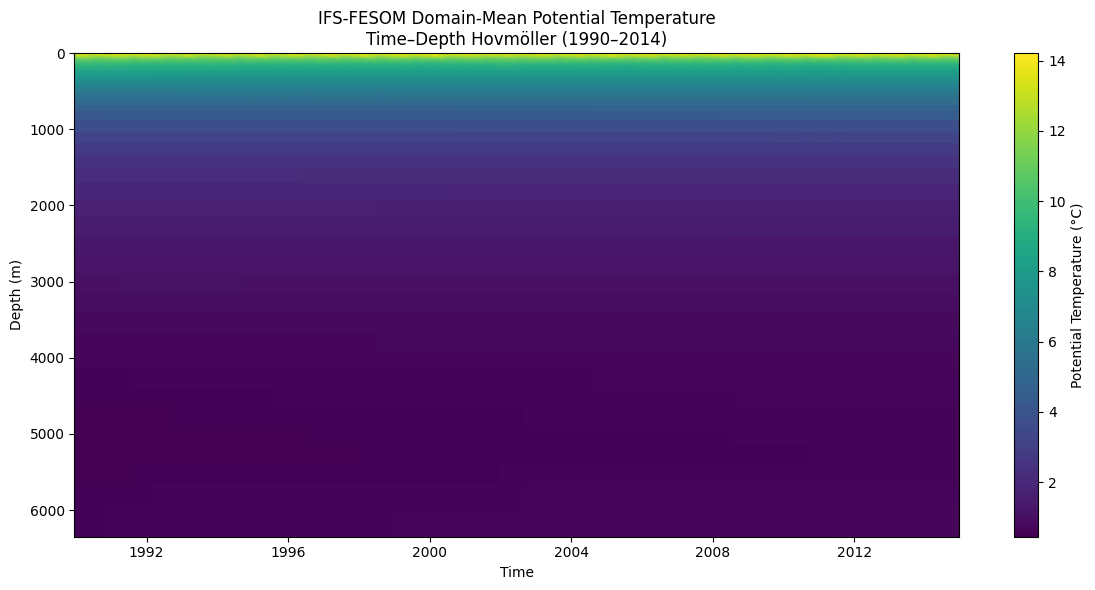

In [7]:
# STEP 4: Load domain-mean thetao and create a time–depth (Hovmöller) plot

import xarray as xr
import matplotlib.pyplot as plt

# Load processed dataset
path = f"{EVA_DIR}/thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc"
da = xr.open_dataarray(path)

# Convert temperature to °C for readability (optional but common)
thetao_c = da - 273.15
thetao_c.attrs["units"] = "°C"

# Create Hovmöller plot
plt.figure(figsize=(12, 6))

pcm = plt.pcolormesh(
    thetao_c["time"],
    thetao_c["level"],
    thetao_c.T,
    shading="auto"
)

# Invert depth axis (surface at top)
plt.gca().invert_yaxis()

# Labels and title
plt.xlabel("Time")
plt.ylabel("Depth (m)")
plt.title("IFS-FESOM Domain-Mean Potential Temperature\nTime–Depth Hovmöller (1990–2014)")

# Colorbar
cbar = plt.colorbar(pcm)
cbar.set_label("Potential Temperature (°C)")

plt.tight_layout()
plt.show()

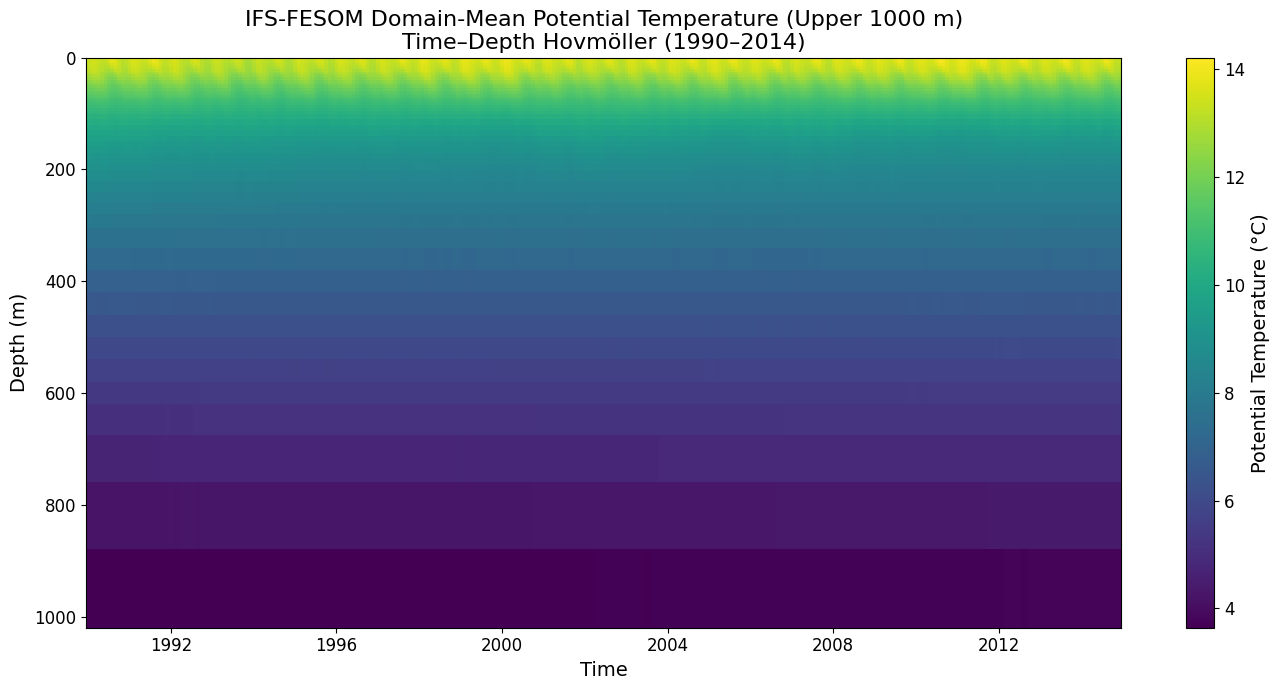

In [8]:
# STEP 4 (refined): Plot time–depth Hovmöller of domain-mean thetao
#                   limited to upper 1000 m with larger labels

import xarray as xr
import matplotlib.pyplot as plt

# Load processed data
path = f"{EVA_DIR}/thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc"
da = xr.open_dataarray(path)

# Convert to °C
thetao_c = da - 273.15
thetao_c.attrs["units"] = "°C"

# Select upper 1000 m
thetao_1000 = thetao_c.sel(level=slice(0, 1000))

# Plot
plt.figure(figsize=(14, 7))

pcm = plt.pcolormesh(
    thetao_1000["time"],
    thetao_1000["level"],
    thetao_1000.T,
    shading="auto"
)

# Depth axis: surface on top
plt.gca().invert_yaxis()

# Labels and title (bigger fonts)
plt.xlabel("Time", fontsize=14)
plt.ylabel("Depth (m)", fontsize=14)
plt.title(
    "IFS-FESOM Domain-Mean Potential Temperature (Upper 1000 m)\n"
    "Time–Depth Hovmöller (1990–2014)",
    fontsize=16
)

# Colorbar
cbar = plt.colorbar(pcm)
cbar.set_label("Potential Temperature (°C)", fontsize=14)
cbar.ax.tick_params(labelsize=12)

# Tick sizes
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

## Compute anomalies relative to Jan 1990 and plot Hovmöller (0–1000 m)

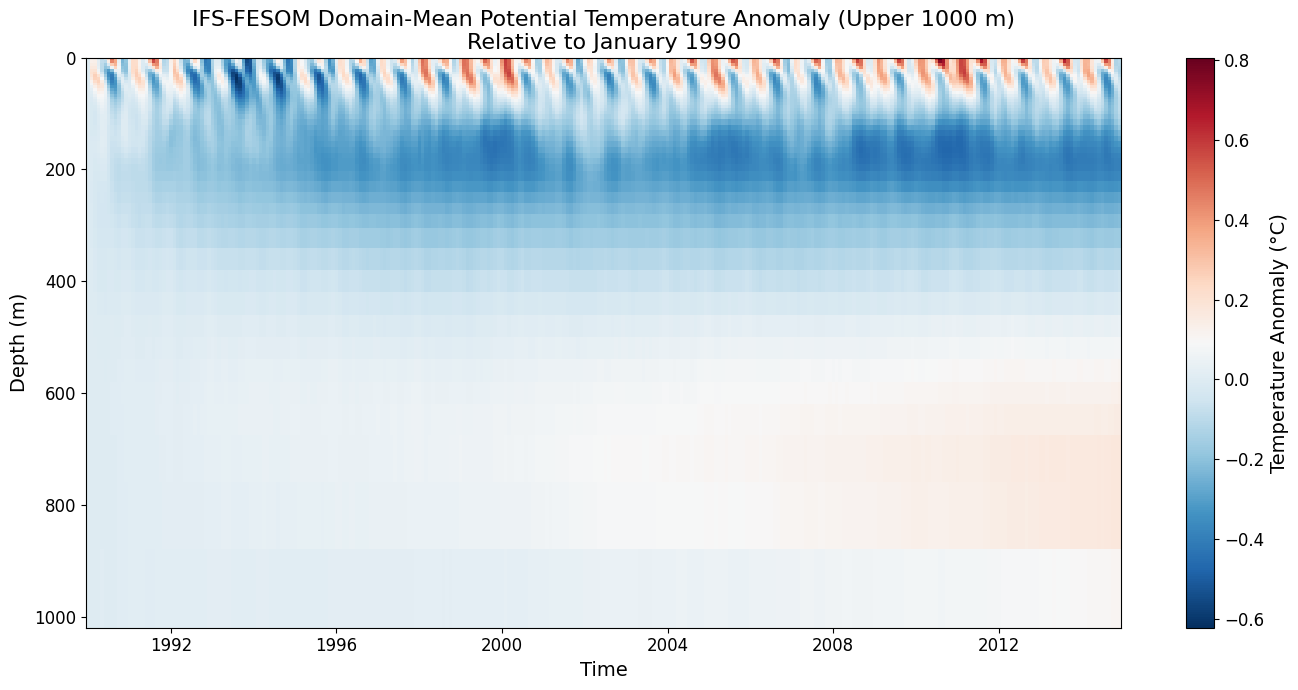

In [9]:
# STEP 5: Plot time–depth thetao anomalies relative to Jan 1990 (upper 1000 m)

import xarray as xr
import matplotlib.pyplot as plt

# Load processed data
path = f"{EVA_DIR}/thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc"
da = xr.open_dataarray(path)

# Convert to °C
thetao_c = da - 273.15
thetao_c.attrs["units"] = "°C"

# Select reference timestep: January 1990
ref = thetao_c.sel(time="1990-01-01")

# Compute anomaly
thetao_anom = thetao_c - ref

# Select upper 1000 m
thetao_anom_1000 = thetao_anom.sel(level=slice(0, 1000))

# Plot
plt.figure(figsize=(14, 7))

pcm = plt.pcolormesh(
    thetao_anom_1000["time"],
    thetao_anom_1000["level"],
    thetao_anom_1000.T,
    shading="auto",
    cmap="RdBu_r"
)

# Depth axis
plt.gca().invert_yaxis()

# Labels and title
plt.xlabel("Time", fontsize=14)
plt.ylabel("Depth (m)", fontsize=14)
plt.title(
    "IFS-FESOM Domain-Mean Potential Temperature Anomaly (Upper 1000 m)\n"
    "Relative to January 1990",
    fontsize=16
)

# Colorbar
cbar = plt.colorbar(pcm)
cbar.set_label("Temperature Anomaly (°C)", fontsize=14)
cbar.ax.tick_params(labelsize=12)

# Ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

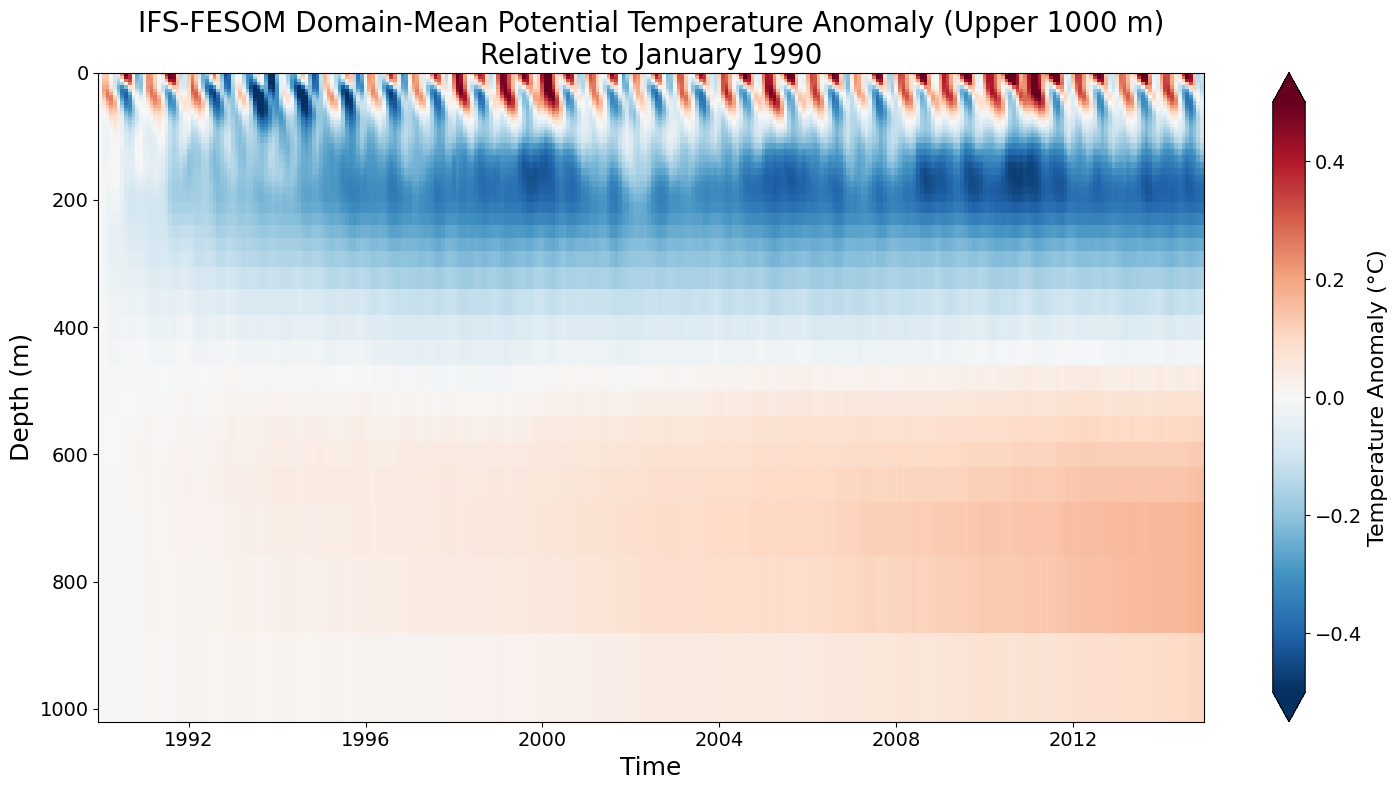

In [11]:
# STEP 5 (refined): Plot time–depth thetao anomalies relative to Jan 1990
#                   with fixed ±5 °C color scale and emphasized labels

import xarray as xr
import matplotlib.pyplot as plt

# Load processed data
path = f"{EVA_DIR}/thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc"
da = xr.open_dataarray(path)

# Convert to °C
thetao_c = da - 273.15
thetao_c.attrs["units"] = "°C"

# Reference: January 1990
ref = thetao_c.sel(time="1990-01-01")

# Anomaly
thetao_anom = thetao_c - ref

# Upper 1000 m
thetao_anom_1000 = thetao_anom.sel(level=slice(0, 1000))

# Plot
plt.figure(figsize=(15, 8))

pcm = plt.pcolormesh(
    thetao_anom_1000["time"],
    thetao_anom_1000["level"],
    thetao_anom_1000.T,
    shading="auto",
    cmap="RdBu_r",
    vmin=-0.5,
    vmax=0.5
)

# Invert depth axis
plt.gca().invert_yaxis()

# Labels and title (larger fonts)
plt.xlabel("Time", fontsize=18)
plt.ylabel("Depth (m)", fontsize=18)
plt.title(
    "IFS-FESOM Domain-Mean Potential Temperature Anomaly (Upper 1000 m)\n"
    "Relative to January 1990",
    fontsize=20
)

# Colorbar with pointed ends
cbar = plt.colorbar(pcm, extend="both")
cbar.set_label("Temperature Anomaly (°C)", fontsize=16)
cbar.ax.tick_params(labelsize=14)

# Tick sizes
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()

# 3 models & EN4

## Create 1990–2014 time–depth thetao & save

In [1]:
# STEP 3 (IFS-NEMO): Create 1990–2014 time–depth thetao
#                   by spatially averaging each year and concatenating in time

import xarray as xr
import glob

# Directory and file pattern
data_dir = f"{LRA_ROOT}/climatedt-o25.1/IFS-NEMO/historical-1990/r100/monthly/"
files = sorted(glob.glob(data_dir + "thetao_o007_r100_monthly_*.nc"))

print(f"Number of files found (IFS-NEMO): {len(files)}")

thetao_list = []

for f in files:
    ds = xr.open_dataset(f)
    
    # Spatial mean
    thetao_mean = ds["thetao"].mean(dim=("lat", "lon"))
    
    # Metadata
    thetao_mean.attrs["long_name"] = "Domain-mean sea water potential temperature"
    thetao_mean.attrs["units"] = "K"
    thetao_mean.attrs["source"] = "IFS-NEMO"
    
    thetao_list.append(thetao_mean)

# Concatenate and sort
thetao_td_nemo = xr.concat(thetao_list, dim="time").sortby("time")

# Check
print(thetao_td_nemo)
print("Time range:", thetao_td_nemo.time.values[[0, -1]])

Number of files found (IFS-NEMO): 25
<xarray.DataArray 'thetao' (time: 300, level: 75)>
array([[286.73618646, 286.70865909, 286.69216498, ..., 274.05973814,
        274.09385702,          nan],
       [286.76627672, 286.74164362, 286.72835403, ..., 274.06001067,
        274.09415312,          nan],
       [286.74867379, 286.72231949, 286.7090929 , ..., 274.06026657,
        274.09453398,          nan],
       ...,
       [286.89096682, 286.86349052, 286.84985495, ..., 274.07763916,
        274.10740815,          nan],
       [286.66473793, 286.6388581 , 286.62435312, ..., 274.07769598,
        274.10747796,          nan],
       [286.59239945, 286.56709871, 286.55196243, ..., 274.07775483,
        274.10755218,          nan]])
Coordinates:
  * level      (level) float64 0.5058 1.556 2.668 ... 5.698e+03 5.902e+03
    idx_level  (level) int64 0 1 2 3 4 5 6 7 8 9 ... 66 67 68 69 70 71 72 73 74
  * time       (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01
Attributes:
    long_n

In [3]:
# STEP 3b (IFS-NEMO): Save the domain-mean time–depth thetao dataset to NetCDF

import os

out_dir = f"{EVA_DIR}/"
out_file = "thetao_domainmean_IFS-NEMO_time_depth_1990_2014.nc"

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(out_dir, out_file)

thetao_td_nemo.to_netcdf(
    out_path,
    encoding={"thetao": {"zlib": True, "complevel": 4}}
)

print(f"Saved IFS-NEMO file to:\n{out_path}")

Saved IFS-NEMO file to:
<EVA_DIR>/thetao_domainmean_IFS-NEMO_time_depth_1990_2014.nc


In [2]:
# STEP 3 (ICON): Create 1990–2014 time–depth thetao
#                by spatially averaging each year and concatenating in time

import xarray as xr
import glob

# Directory and file pattern
data_dir = f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/"
files = sorted(glob.glob(data_dir + "thetao_o00k_r100_monthly_*.nc"))

print(f"Number of files found (ICON): {len(files)}")

thetao_list = []

for f in files:
    ds = xr.open_dataset(f)
    
    # Spatial mean
    thetao_mean = ds["thetao"].mean(dim=("lat", "lon"))
    
    # Metadata
    thetao_mean.attrs["long_name"] = "Domain-mean sea water potential temperature"
    thetao_mean.attrs["units"] = "K"
    thetao_mean.attrs["source"] = "ICON"
    
    thetao_list.append(thetao_mean)

# Concatenate and sort
thetao_td_icon = xr.concat(thetao_list, dim="time").sortby("time")

# Check
print(thetao_td_icon)
print("Time range:", thetao_td_icon.time.values[[0, -1]])

Number of files found (ICON): 25
<xarray.DataArray 'thetao' (time: 300, level: 72)>
array([[286.92637355, 286.89252119, 286.86575932, ..., 274.00440587,
        274.07968702, 274.11219815],
       [287.13175574, 287.10643144, 287.09065716, ..., 274.00449984,
        274.07995357, 274.11245398],
       [287.03976763, 287.01460502, 287.0010977 , ..., 274.00467335,
        274.08012958, 274.112492  ],
       ...,
       [286.78959831, 286.77676166, 286.77118201, ..., 274.03874672,
        274.11097938, 274.14157412],
       [286.45824657, 286.44119891, 286.43210825, ..., 274.03894631,
        274.11118033, 274.14175049],
       [286.50664103, 286.48377506, 286.46835432, ..., 274.03911231,
        274.11136284, 274.14188439]])
Coordinates:
  * level      (level) float64 1.0 3.1 5.45 ... 5.279e+03 5.546e+03 5.816e+03
    idx_level  (level) int64 0 1 2 3 4 5 6 7 8 9 ... 63 64 65 66 67 68 69 70 71
  * time       (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01
Attributes:
    long_n

In [4]:
# STEP 3b (ICON): Save the domain-mean time–depth thetao dataset to NetCDF

import os

out_dir = f"{EVA_DIR}/"
out_file = "thetao_domainmean_ICON_time_depth_1990_2014.nc"

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(out_dir, out_file)

thetao_td_icon.to_netcdf(
    out_path,
    encoding={"thetao": {"zlib": True, "complevel": 4}}
)

print(f"Saved ICON file to:\n{out_path}")

Saved ICON file to:
<EVA_DIR>/thetao_domainmean_ICON_time_depth_1990_2014.nc


## Plot 

In [5]:
# STEP 5a: Load all domain-mean time–depth thetao datasets

import xarray as xr

base_path = f"{EVA_DIR}/"

paths = {
    "IFS-FESOM": base_path + "thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc",
    "IFS-NEMO":  base_path + "thetao_domainmean_IFS-NEMO_time_depth_1990_2014.nc",
    "ICON":      base_path + "thetao_domainmean_ICON_time_depth_1990_2014.nc",
}

# Load as DataArrays
thetao = {name: xr.open_dataarray(path) for name, path in paths.items()}

print("Loaded datasets:")
for k, v in thetao.items():
    print(f"{k}: {v.shape}")

Loaded datasets:
IFS-FESOM: (300, 69)
IFS-NEMO: (300, 75)
ICON: (300, 72)


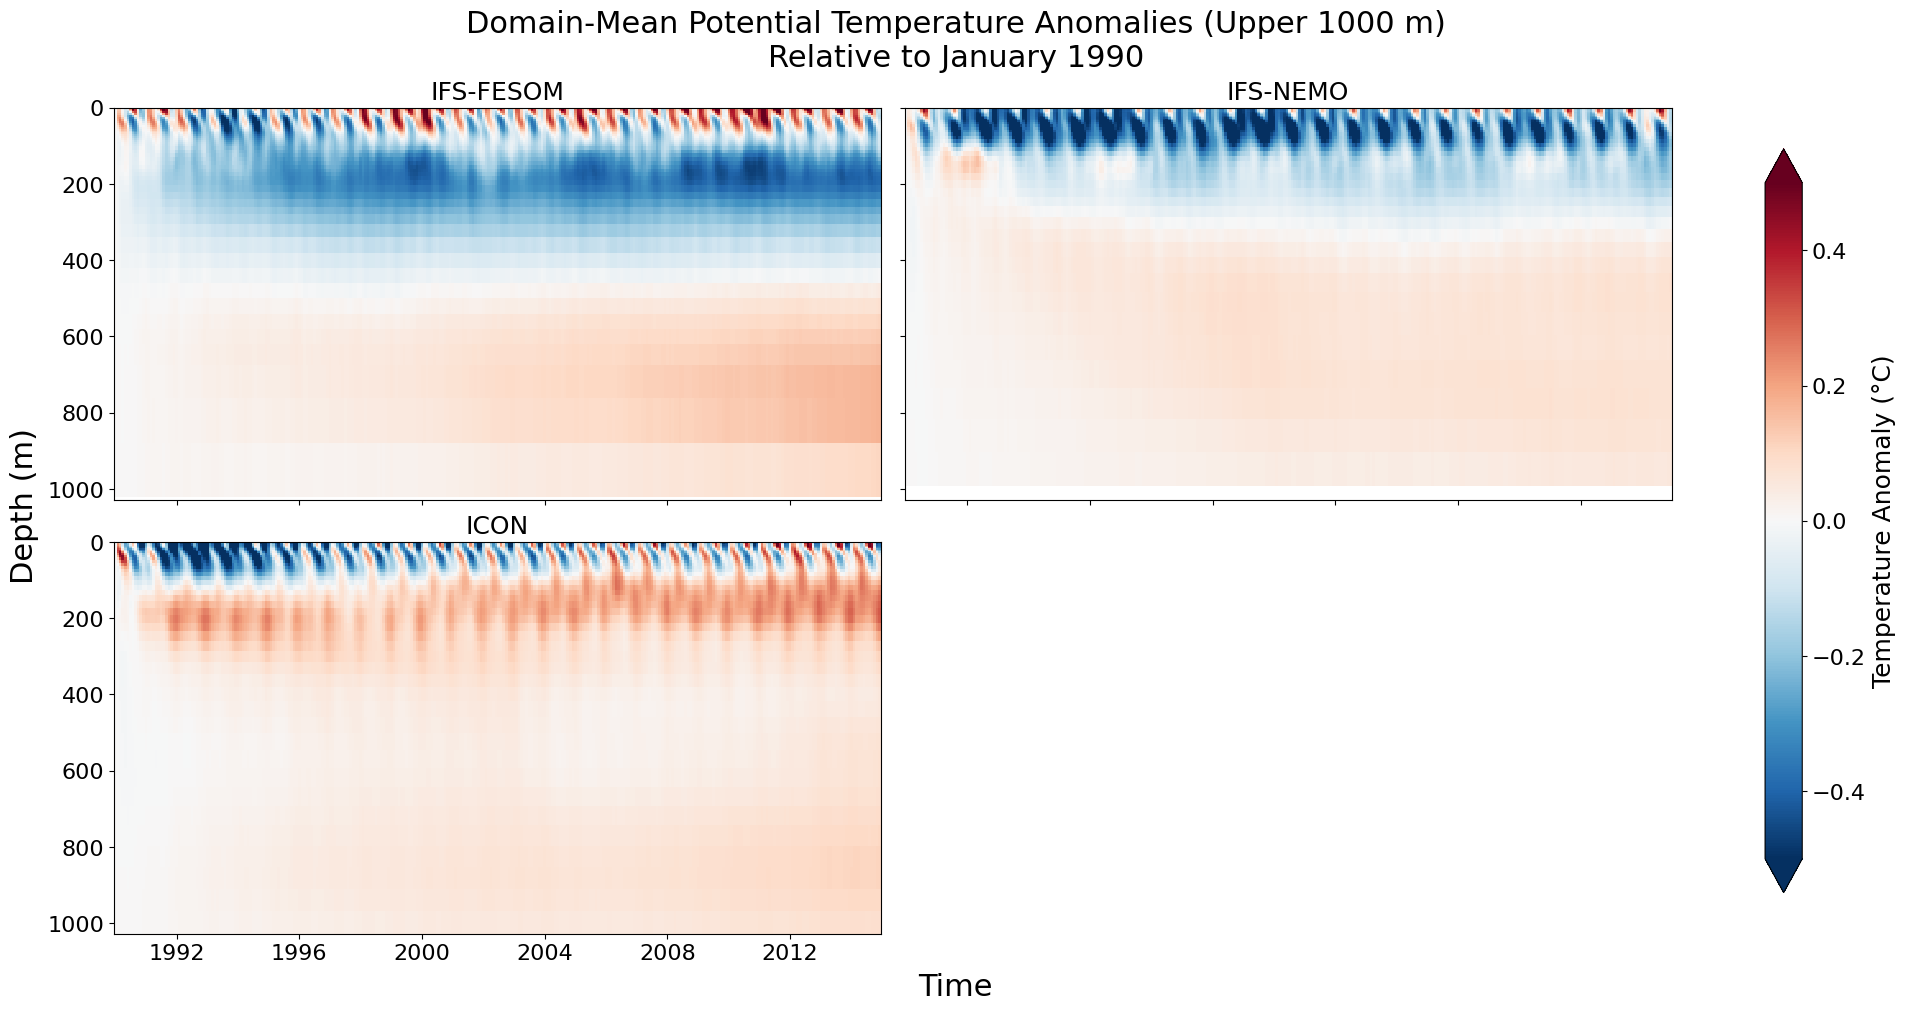

In [7]:
# STEP 5b (fixed): Plot time–depth thetao anomalies (relative to Jan 1990)
#                  2x2 layout, non-overlapping colorbar, larger labels

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True   # <<< key for spacing
)
axes = axes.flatten()

for ax, (model, da) in zip(axes, thetao.items()):
    
    # Convert to °C
    da_c = da - 273.15
    da_c.attrs["units"] = "°C"

    # Reference: January 1990
    ref = da_c.sel(time="1990-01-01")

    # Anomaly
    anom = da_c - ref

    # Upper 1000 m
    anom_1000 = anom.sel(level=slice(0, 1000))

    pcm = ax.pcolormesh(
        anom_1000["time"],
        anom_1000["level"],
        anom_1000.T,
        shading="auto",
        cmap="RdBu_r",
        vmin=-0.5,
        vmax=0.5
    )

    ax.invert_yaxis()
    ax.set_title(model, fontsize=18)
    ax.tick_params(labelsize=16)

# Turn off 4th panel
axes[3].axis("off")

# Big common labels
fig.supxlabel("Time", fontsize=22)
fig.supylabel("Depth (m)", fontsize=22)

# Colorbar (no overlap, pointed ends)
cbar = fig.colorbar(
    pcm,
    ax=axes[:3],
    orientation="vertical",
    extend="both",
    shrink=0.9,
    pad=0.06      # <<< extra spacing from panels
)
cbar.set_label("Temperature Anomaly (°C)", fontsize=18)
cbar.ax.tick_params(labelsize=16)

fig.suptitle(
    "Domain-Mean Potential Temperature Anomalies (Upper 1000 m)\n"
    "Relative to January 1990",
    fontsize=22
)

plt.show()

In [8]:
import xarray as xr

paths = {
    "IFS-FESOM": f"{EVA_DIR}/thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc",
    "IFS-NEMO":  f"{EVA_DIR}/thetao_domainmean_IFS-NEMO_time_depth_1990_2014.nc",
    "ICON":      f"{EVA_DIR}/thetao_domainmean_ICON_time_depth_1990_2014.nc",
}

for model, path in paths.items():
    da = xr.open_dataarray(path)
    
    # Identify vertical coordinate name (usually "level")
    z = da.coords["level"]
    
    print(f"\n===== {model} =====")
    print(f"Shape (time, level): {da.shape}")
    print(f"Number of vertical levels: {z.size}")
    print(f"Depth range: {float(z.min()):.1f} m  →  {float(z.max()):.1f} m")
    
    print("First 5 levels (m):")
    print(z.values[:5])
    
    print("Last 5 levels (m):")
    print(z.values[-5:])


===== IFS-FESOM =====
Shape (time, level): (300, 69)
Number of vertical levels: 69
Depth range: 2.5 m  →  6175.0 m
First 5 levels (m):
[ 2.5  7.5 12.5 17.5 22.5]
Last 5 levels (m):
[5025. 5275. 5525. 5825. 6175.]

===== IFS-NEMO =====
Shape (time, level): (300, 75)
Number of vertical levels: 75
Depth range: 0.5 m  →  5902.1 m
First 5 levels (m):
[0.50576001 1.55585527 2.66768169 3.85627985 5.14036131]
Last 5 levels (m):
[5089.47851562 5291.68310547 5494.57519531 5698.06054688 5902.05761719]

===== ICON =====
Shape (time, level): (300, 72)
Number of vertical levels: 72
Depth range: 1.0 m  →  5815.8 m
First 5 levels (m):
[ 1.    3.1   5.45  8.1  11.05]
Last 5 levels (m):
[4753.55 5014.   5278.6  5546.25 5815.75]


## EN4

In [4]:
# STEP 1: Collect EN4 monthly analysis files for 1990–2014 only

import glob
import os

data_dir = f"{EN4_DIR}/extracted/"

# Get all EN4 analysis files
all_files = sorted(glob.glob(
    os.path.join(data_dir, "EN.4.2.2.f.analysis.g10.*.nc")
))

print(f"Total EN4 files found: {len(all_files)}")

# Filter files by year in filename (YYYYMM)
files_1990_2014 = []

for f in all_files:
    fname = os.path.basename(f)
    year = int(fname.split(".")[-2][:4])  # extracts YYYY
    
    if 1990 <= year <= 2014:
        files_1990_2014.append(f)

print(f"EN4 files for 1990–2014: {len(files_1990_2014)}")

# Quick sanity check
print("First file:", os.path.basename(files_1990_2014[0]))
print("Last file :", os.path.basename(files_1990_2014[-1]))

Total EN4 files found: 1511
EN4 files for 1990–2014: 300
First file: EN.4.2.2.f.analysis.g10.199001.nc
Last file : EN.4.2.2.f.analysis.g10.201412.nc


In [5]:
# STEP 2: Inspect one EN4 monthly file

import xarray as xr

sample_file = f"{EN4_DIR}/extracted/EN.4.2.2.f.analysis.g10.199001.nc"
ds = xr.open_dataset(sample_file)

print(ds)

<xarray.Dataset>
Dimensions:                          (depth: 42, lat: 173, lon: 360, time: 1,
                                      bnds: 2)
Coordinates:
  * depth                            (depth) float32 5.022 15.08 ... 5.35e+03
  * lat                              (lat) float32 -83.0 -82.0 ... 88.0 89.0
  * lon                              (lon) float32 1.0 2.0 3.0 ... 359.0 360.0
  * time                             (time) datetime64[ns] 1990-01-16T12:00:00
Dimensions without coordinates: bnds
Data variables:
    temperature                      (time, depth, lat, lon) float32 ...
    salinity                         (time, depth, lat, lon) float32 ...
    temperature_uncertainty          (time, depth, lat, lon) float32 ...
    salinity_uncertainty             (time, depth, lat, lon) float32 ...
    temperature_observation_weights  (time, depth, lat, lon) float32 ...
    salinity_observation_weights     (time, depth, lat, lon) float32 ...
    time_bnds                        (tim

In [6]:
print(ds["temperature"])
print("Units:", ds["temperature"].attrs.get("units", "not found"))

<xarray.DataArray 'temperature' (time: 1, depth: 42, lat: 173, lon: 360)>
[2615760 values with dtype=float32]
Coordinates:
  * depth    (depth) float32 5.022 15.08 25.16 ... 4.752e+03 5.051e+03 5.35e+03
  * lat      (lat) float32 -83.0 -82.0 -81.0 -80.0 -79.0 ... 86.0 87.0 88.0 89.0
  * lon      (lon) float32 1.0 2.0 3.0 4.0 5.0 ... 356.0 357.0 358.0 359.0 360.0
  * time     (time) datetime64[ns] 1990-01-16T12:00:00
Attributes:
    long_name:      temperature
    standard_name:  sea_water_potential_temperature
    units:          kelvin
    valid_min:      -5.0
    valid_max:      45.0
Units: kelvin


In [7]:
print("Depth range:", ds.depth.values[[0, -1]])
print("Number of depth levels:", ds.depth.size)

Depth range: [5.0215898e+00 5.3502720e+03]
Number of depth levels: 42


In [8]:
# STEP 3 (EN4): Create 1990–2014 time–depth temperature dataset
#               by spatially averaging each monthly EN4 file

import xarray as xr

thetao_list = []

for f in files_1990_2014:
    ds = xr.open_dataset(f)
    
    # Spatial mean (lat, lon)
    temp_mean = ds["temperature"].mean(dim=("lat", "lon"), skipna=True)
    
    # Keep metadata clean and comparable
    temp_mean.attrs["long_name"] = "Domain-mean sea water potential temperature"
    temp_mean.attrs["units"] = "K"
    temp_mean.attrs["source"] = "EN4"
    
    thetao_list.append(temp_mean)

# Concatenate along time
thetao_td_en4 = xr.concat(thetao_list, dim="time")

# Sort by time (important!)
thetao_td_en4 = thetao_td_en4.sortby("time")

# Quick checks
print(thetao_td_en4)
print("Time range:", thetao_td_en4.time.values[[0, -1]])
print("Depth range:", thetao_td_en4.depth.values[[0, -1]])

<xarray.DataArray 'temperature' (time: 300, depth: 42)>
array([[286.73517, 286.73398, 286.6653 , ..., 273.93716, 273.93802,
        274.01086],
       [286.943  , 286.9212 , 286.8296 , ..., 273.93988, 273.93896,
        274.01105],
       [286.9206 , 286.92526, 286.8677 , ..., 273.93848, 273.93796,
        274.01096],
       ...,
       [286.86548, 286.83258, 286.7345 , ..., 273.9395 , 273.93622,
        274.01157],
       [286.6999 , 286.66943, 286.5872 , ..., 273.93967, 273.93713,
        274.01215],
       [286.74594, 286.70636, 286.59747, ..., 273.94186, 273.93958,
        274.01242]], dtype=float32)
Coordinates:
  * depth    (depth) float32 5.022 15.08 25.16 ... 4.752e+03 5.051e+03 5.35e+03
  * time     (time) datetime64[ns] 1990-01-16T12:00:00 ... 2014-12-16T12:00:00
Attributes:
    long_name:  Domain-mean sea water potential temperature
    units:      K
    source:     EN4
Time range: ['1990-01-16T12:00:00.000000000' '2014-12-16T12:00:00.000000000']
Depth range: [5.0215898e+00 

In [9]:
# STEP 3b (EN4): Save the domain-mean time–depth temperature dataset to NetCDF

import os

# Output directory and file name
out_dir = f"{EVA_DIR}/"
out_file = "temperature_domainmean_EN4_time_depth_1990_2014.nc"

# Ensure directory exists
os.makedirs(out_dir, exist_ok=True)

# Full output path
out_path = os.path.join(out_dir, out_file)

# Save with compression
thetao_td_en4.to_netcdf(
    out_path,
    encoding={"temperature": {"zlib": True, "complevel": 4}}
)

print(f"Saved EN4 file to:\n{out_path}")

Saved EN4 file to:
<EVA_DIR>/temperature_domainmean_EN4_time_depth_1990_2014.nc


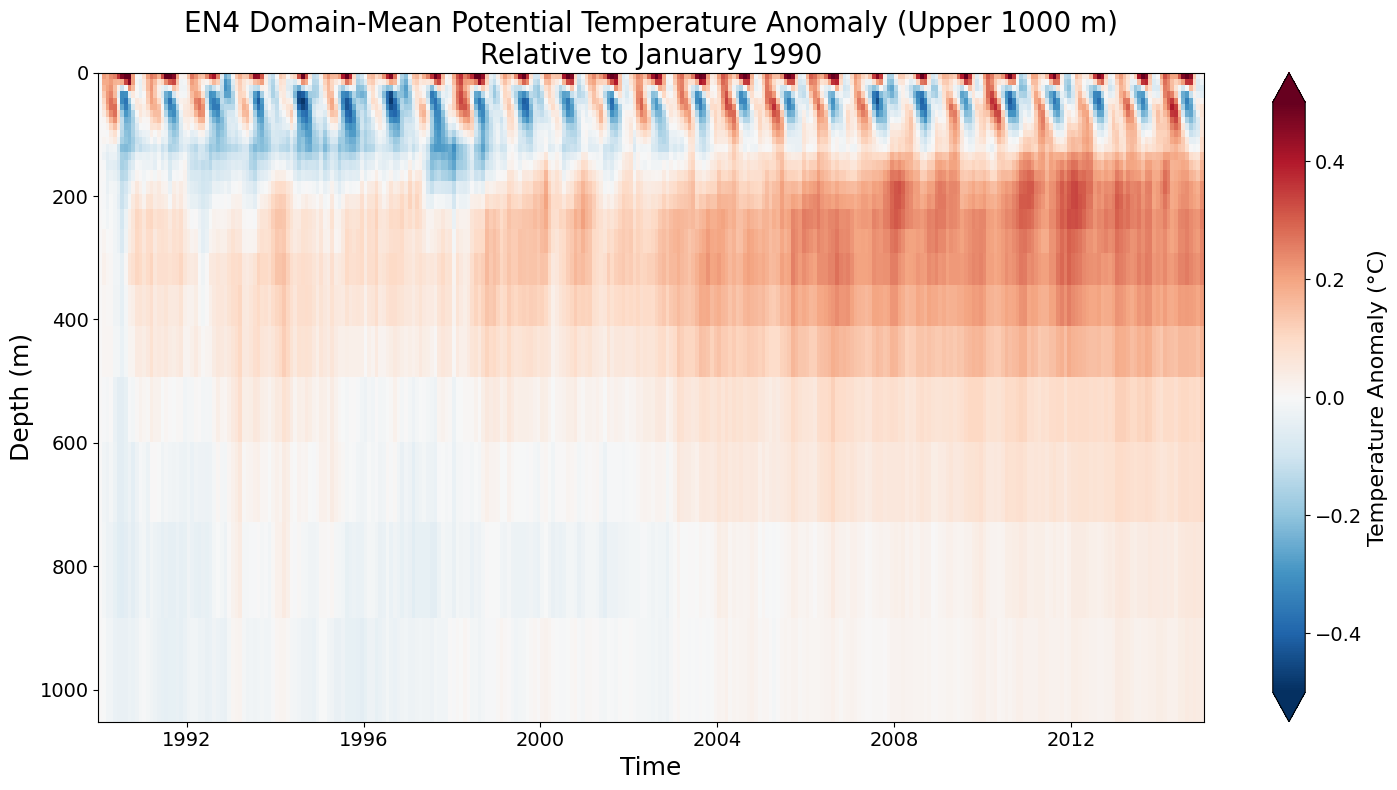

In [10]:
# STEP 4 (EN4): Plot time–depth temperature anomalies relative to Jan 1990
#               for the upper 1000 m

import xarray as xr
import matplotlib.pyplot as plt

# Load processed EN4 data
path = f"{EVA_DIR}/temperature_domainmean_EN4_time_depth_1990_2014.nc"
da = xr.open_dataarray(path)

# Convert to °C
temp_c = da - 273.15
temp_c.attrs["units"] = "°C"

# Reference: January 1990 (first timestep)
ref = temp_c.sel(time=temp_c.time[0])

# Anomaly
temp_anom = temp_c - ref

# Upper 1000 m
temp_anom_1000 = temp_anom.sel(depth=slice(0, 1000))

# Plot
plt.figure(figsize=(15, 8))

pcm = plt.pcolormesh(
    temp_anom_1000["time"],
    temp_anom_1000["depth"],
    temp_anom_1000.T,
    shading="auto",
    cmap="RdBu_r",
    vmin=-0.5,
    vmax=0.5
)

# Invert depth axis
plt.gca().invert_yaxis()

# Labels and title
plt.xlabel("Time", fontsize=18)
plt.ylabel("Depth (m)", fontsize=18)
plt.title(
    "EN4 Domain-Mean Potential Temperature Anomaly (Upper 1000 m)\n"
    "Relative to January 1990",
    fontsize=20
)

# Colorbar with pointed ends
cbar = plt.colorbar(pcm, extend="both")
cbar.set_label("Temperature Anomaly (°C)", fontsize=16)
cbar.ax.tick_params(labelsize=14)

# Tick sizes
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()

## Alll for datasets

In [ ]:
import xarray as xr
import glob
import numpy as np

In [14]:
# STEP 5a: Load EN4 + 3 model domain-mean time-depth datasets

import xarray as xr

base_path = f"{EVA_DIR}/"

paths = {
    "EN4":      base_path + "temperature_domainmean_EN4_time_depth_1990_2014.nc",
    "IFS-FESOM": base_path + "thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc",
    "IFS-NEMO":  base_path + "thetao_domainmean_IFS-NEMO_time_depth_1990_2014.nc",
    "ICON":      base_path + "thetao_domainmean_ICON_time_depth_1990_2014.nc"
}

# Dictionary to hold xarray.DataArrays
thetao = {}

for model, p in paths.items():
    da = xr.open_dataarray(p)
    
    # Standardize coordinate name to 'level' for models, 'depth' for EN4
    if 'depth' in da.coords:
        da = da.rename({'depth': 'level'})
    
    thetao[model] = da

# Quick check
for model, da in thetao.items():
    print(model, da.shape, da.level.values[:5], "...", da.level.values[-5:])

EN4 (300, 42) [ 5.0215898 15.07854   25.16046   35.27829   45.44776  ] ... [4155.628  4453.502  4752.021  5050.9897 5350.272 ]
IFS-FESOM (300, 69) [ 2.5  7.5 12.5 17.5 22.5] ... [5025. 5275. 5525. 5825. 6175.]
IFS-NEMO (300, 75) [0.50576001 1.55585527 2.66768169 3.85627985 5.14036131] ... [5089.47851562 5291.68310547 5494.57519531 5698.06054688 5902.05761719]
ICON (300, 72) [ 1.    3.1   5.45  8.1  11.05] ... [4753.55 5014.   5278.6  5546.25 5815.75]


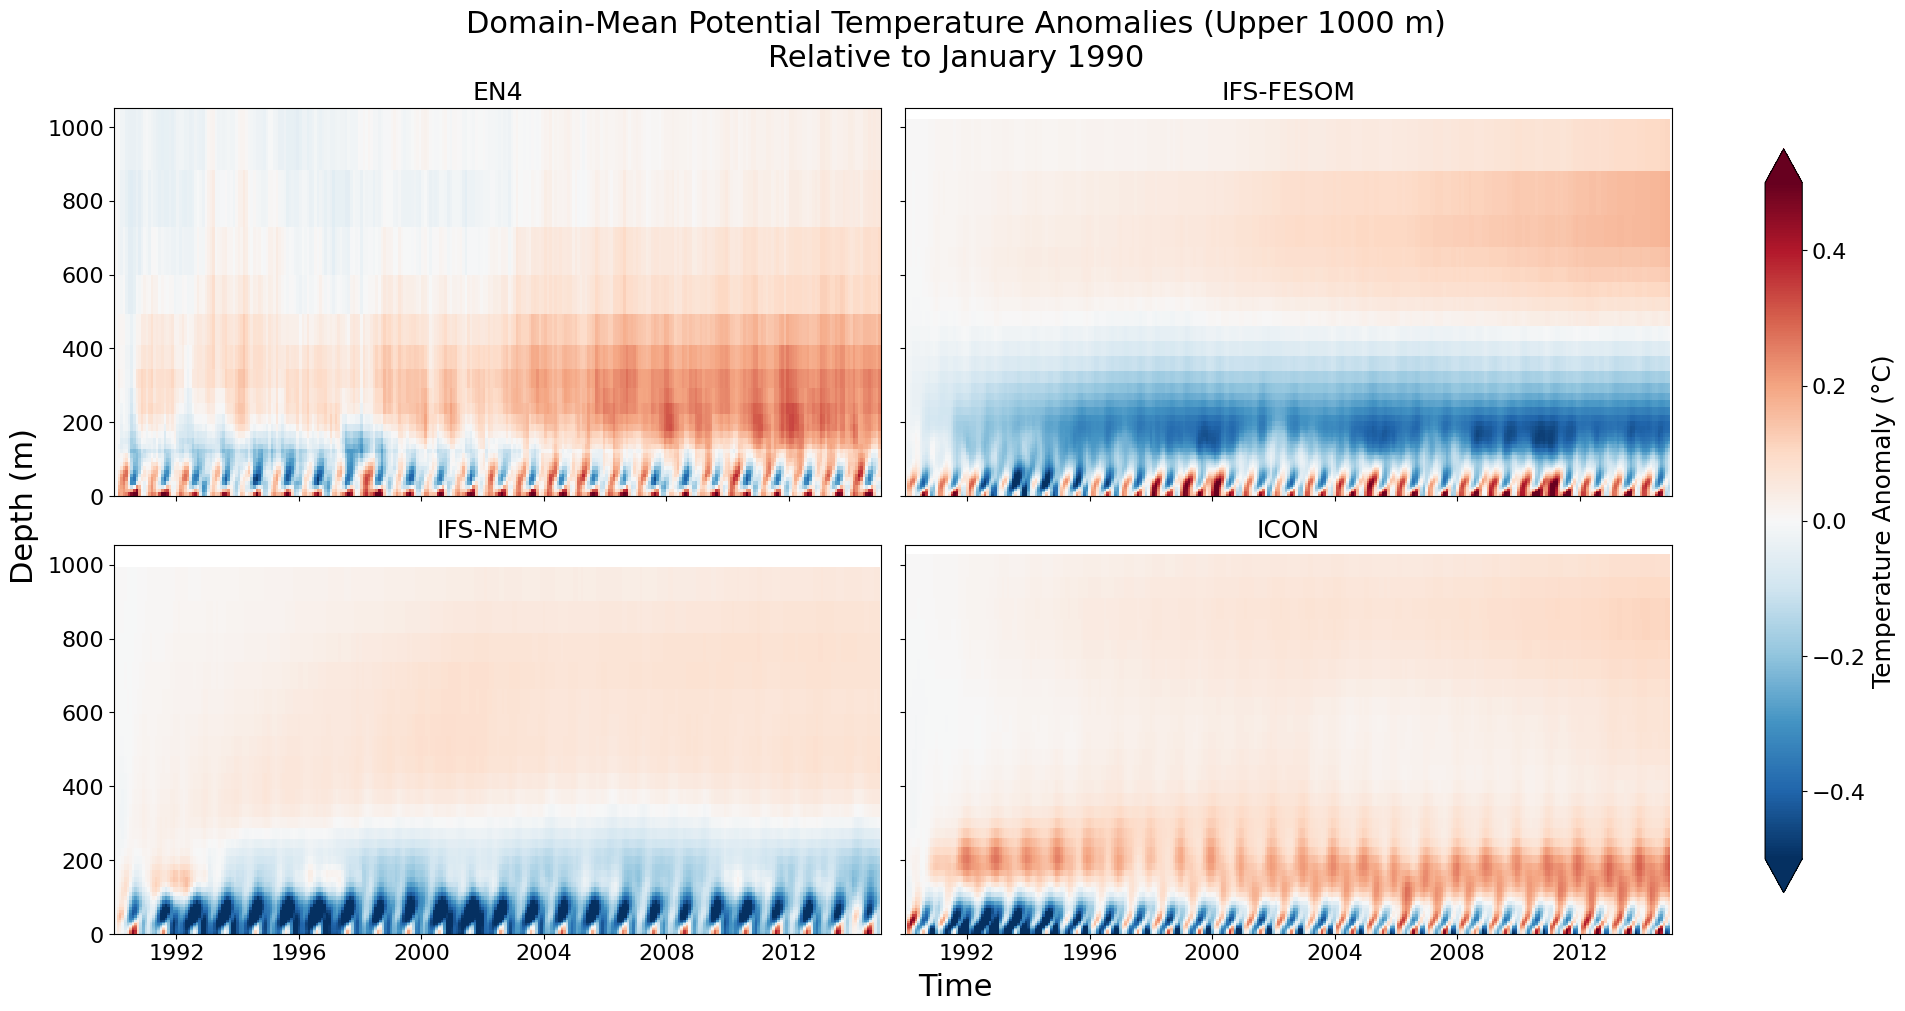

In [17]:
# STEP 5b (inverted): 4-panel Hovmöller plot for EN4 + 3 models
#                     anomalies relative to Jan 1990, upper 1000 m, consistent color scale
#                     0 m at top (surface), 1000 m deeper

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)
axes = axes.flatten()

# Plot order: EN4, IFS-FESOM, IFS-NEMO, ICON
plot_order = ["EN4", "IFS-FESOM", "IFS-NEMO", "ICON"]

for ax, model in zip(axes, plot_order):
    da = thetao[model]
    
    # Convert to °C
    da_c = da - 273.15
    da_c.attrs["units"] = "°C"

    # Reference: first timestep (Jan 1990)
    ref = da_c.sel(time=da_c.time[0])
    
    # Anomaly
    anom = da_c - ref

    # Upper 1000 m
    anom_1000 = anom.sel(level=slice(0, 1000))

    pcm = ax.pcolormesh(
        anom_1000["time"],
        anom_1000["level"],
        anom_1000.T,
        shading="auto",
        cmap="RdBu_r",
        vmin=-0.5,
        vmax=0.5
    )

    ax.invert_yaxis()  # <<< key: invert so 0 m (surface) is at top
    ax.set_title(model, fontsize=18)
    ax.tick_params(labelsize=16)

# Turn off 4th panel (optional)
# axes[3].axis("off")

# Big common labels
fig.supxlabel("Time", fontsize=22)
fig.supylabel("Depth (m)", fontsize=22)

# Colorbar (non-overlapping, pointed ends)
cbar = fig.colorbar(
    pcm,
    ax=axes[:3],
    orientation="vertical",
    extend="both",
    shrink=0.9,
    pad=0.06
)
cbar.set_label("Temperature Anomaly (°C)", fontsize=18)
cbar.ax.tick_params(labelsize=16)

fig.suptitle(
    "Domain-Mean Potential Temperature Anomalies (Upper 1000 m)\n"
    "Relative to January 1990",
    fontsize=22
)

plt.show()

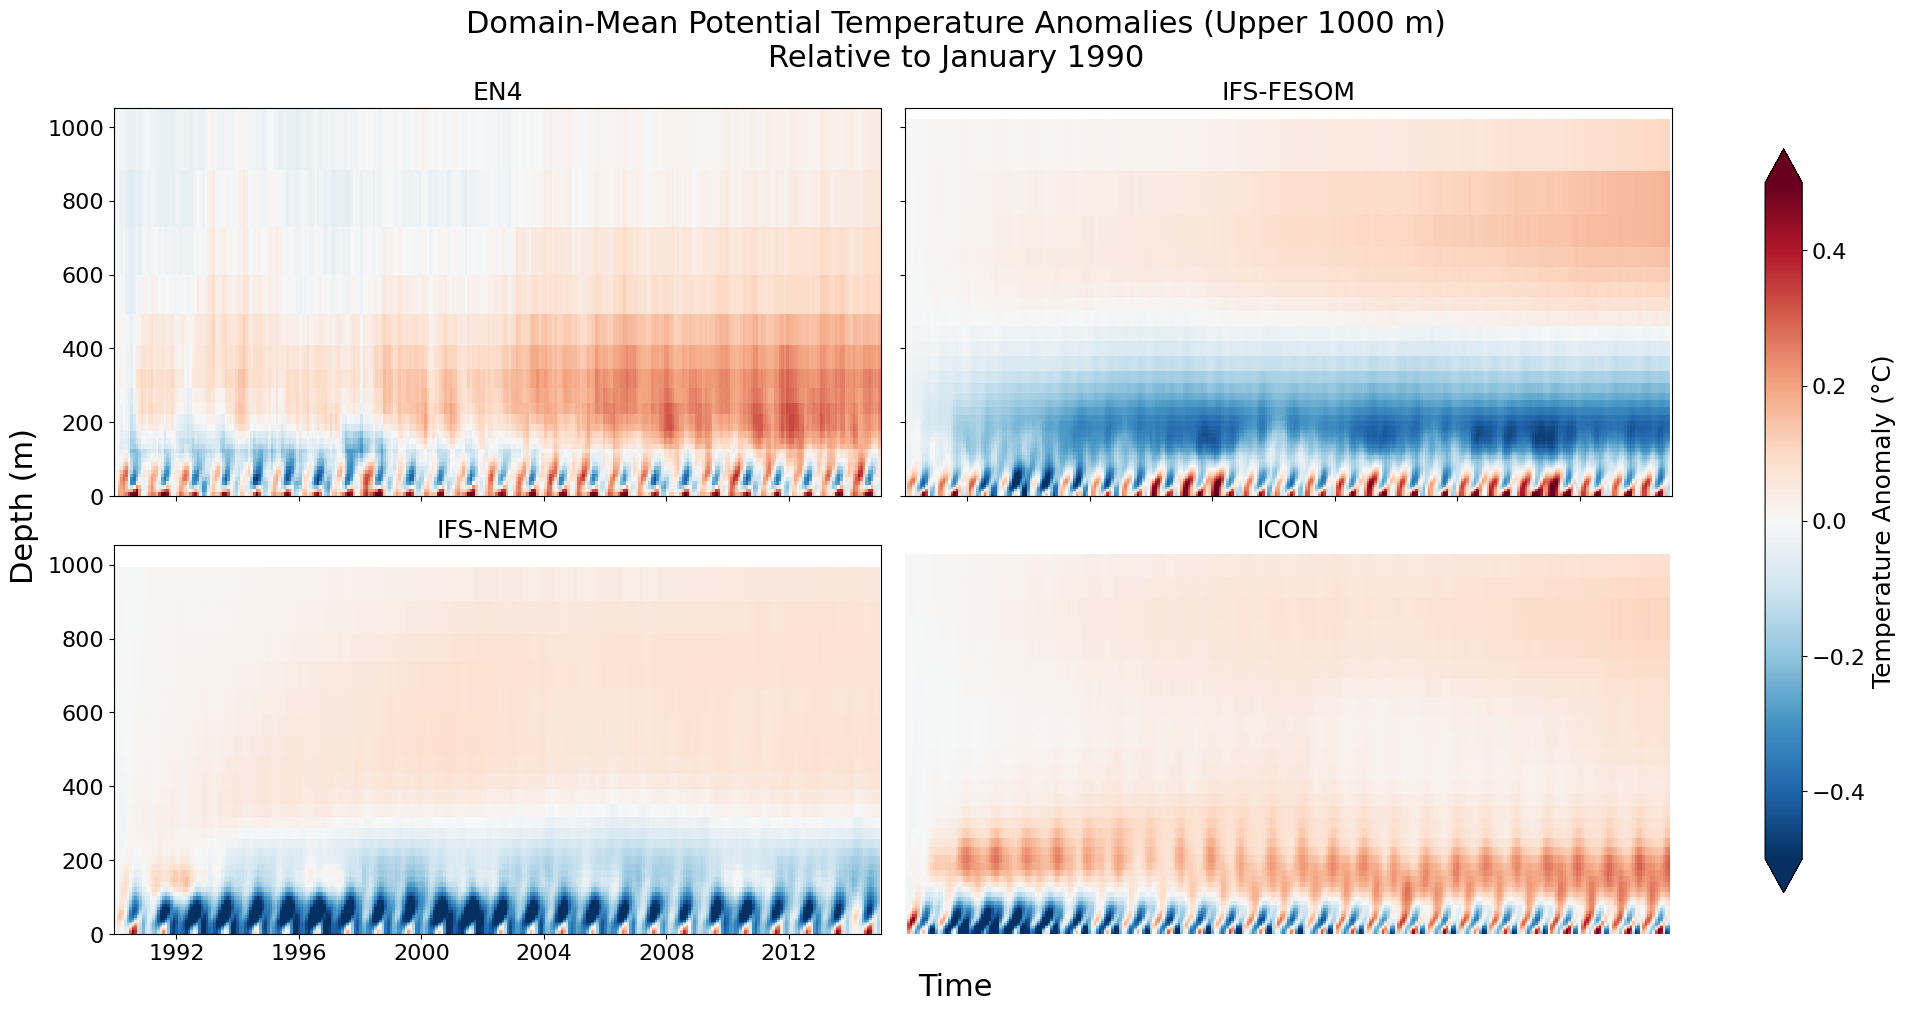

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)
axes = axes.flatten()

plot_order = ["EN4", "IFS-FESOM", "IFS-NEMO", "ICON"]

for ax, model in zip(axes, plot_order):
    da = thetao[model]

    # Convert to °C
    da_c = da - 273.15

    # Reference: first timestep
    ref = da_c.sel(time=da_c.time[0])

    # Anomaly
    anom = da_c - ref

    # Upper 1000 m
    anom_1000 = anom.sel(level=slice(0, 1000))

    # Ensure levels are in ascending order (0 at top, 1000 deeper)
    anom_1000 = anom_1000.sortby("level")

    # pcolormesh expects 2D arrays: (y, x) = (level, time)
    pcm = ax.pcolormesh(
        anom_1000["time"],
        anom_1000["level"],
        anom_1000.T,  # transpose to match (level, time)
        shading="auto",
        cmap="RdBu_r",
        vmin=-0.5,
        vmax=0.5
    )

    # Invert y-axis to put 0 m (surface) at top
    ax.invert_yaxis()

    ax.set_title(model, fontsize=18)
    ax.tick_params(labelsize=16)

# Turn off 4th panel if needed
axes[3].axis("off")

# Big common labels
fig.supxlabel("Time", fontsize=22)
fig.supylabel("Depth (m)", fontsize=22)

# Colorbar
cbar = fig.colorbar(
    pcm,
    ax=axes[:3],
    orientation="vertical",
    extend="both",
    shrink=0.9,
    pad=0.06
)
cbar.set_label("Temperature Anomaly (°C)", fontsize=18)
cbar.ax.tick_params(labelsize=16)

fig.suptitle(
    "Domain-Mean Potential Temperature Anomalies (Upper 1000 m)\n"
    "Relative to January 1990",
    fontsize=22
)

plt.show()

In [20]:
import xarray as xr

# Base path
base_path = f"{EVA_DIR}/"

# File paths
paths = {
    "EN4":       base_path + "temperature_domainmean_EN4_time_depth_1990_2014.nc",
    "IFS-FESOM": base_path + "thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc",
    "IFS-NEMO":  base_path + "thetao_domainmean_IFS-NEMO_time_depth_1990_2014.nc",
    "ICON":      base_path + "thetao_domainmean_ICON_time_depth_1990_2014.nc"
}

# Load all datasets into a dict
thetao = {}
for model, path in paths.items():
    da = xr.open_dataarray(path)
    thetao[model] = da
    
    # Use coords['depth'] safely
    depth_range = da.coords['depth'].values[[0, -1]] if 'depth' in da.coords else "No depth coordinate"
    
    print(f"{model}: shape={da.shape}, depth range={depth_range}")

EN4: shape=(300, 42), depth range=[5.0215898e+00 5.3502720e+03]
IFS-FESOM: shape=(300, 69), depth range=No depth coordinate
IFS-NEMO: shape=(300, 75), depth range=No depth coordinate
ICON: shape=(300, 72), depth range=No depth coordinate


In [21]:
import xarray as xr

# Base path
base_path = f"{EVA_DIR}/"

# File paths
paths = {
    "EN4":       base_path + "temperature_domainmean_EN4_time_depth_1990_2014.nc",
    "IFS-FESOM": base_path + "thetao_domainmean_IFS-FESOM_time_depth_1990_2014.nc",
    "IFS-NEMO":  base_path + "thetao_domainmean_IFS-NEMO_time_depth_1990_2014.nc",
    "ICON":      base_path + "thetao_domainmean_ICON_time_depth_1990_2014.nc"
}

# Load datasets into a dict
thetao = {}
for model, path in paths.items():
    da = xr.open_dataarray(path)
    
    # Standardize depth/level coordinate to 'depth' for consistency
    if 'depth' in da.coords:
        depth_name = 'depth'
    elif 'level' in da.coords:
        depth_name = 'level'
        da = da.rename({'level':'depth'})  # rename level -> depth
    else:
        raise ValueError(f"No recognizable vertical coordinate in {model}")
    
    thetao[model] = da
    print(f"{model}: shape={da.shape}, depth range={da.coords['depth'].values[[0,-1]]}")

EN4: shape=(300, 42), depth range=[5.0215898e+00 5.3502720e+03]
IFS-FESOM: shape=(300, 69), depth range=[2.500e+00 6.175e+03]
IFS-NEMO: shape=(300, 75), depth range=[5.05760014e-01 5.90205762e+03]
ICON: shape=(300, 72), depth range=[1.00000e+00 5.81575e+03]


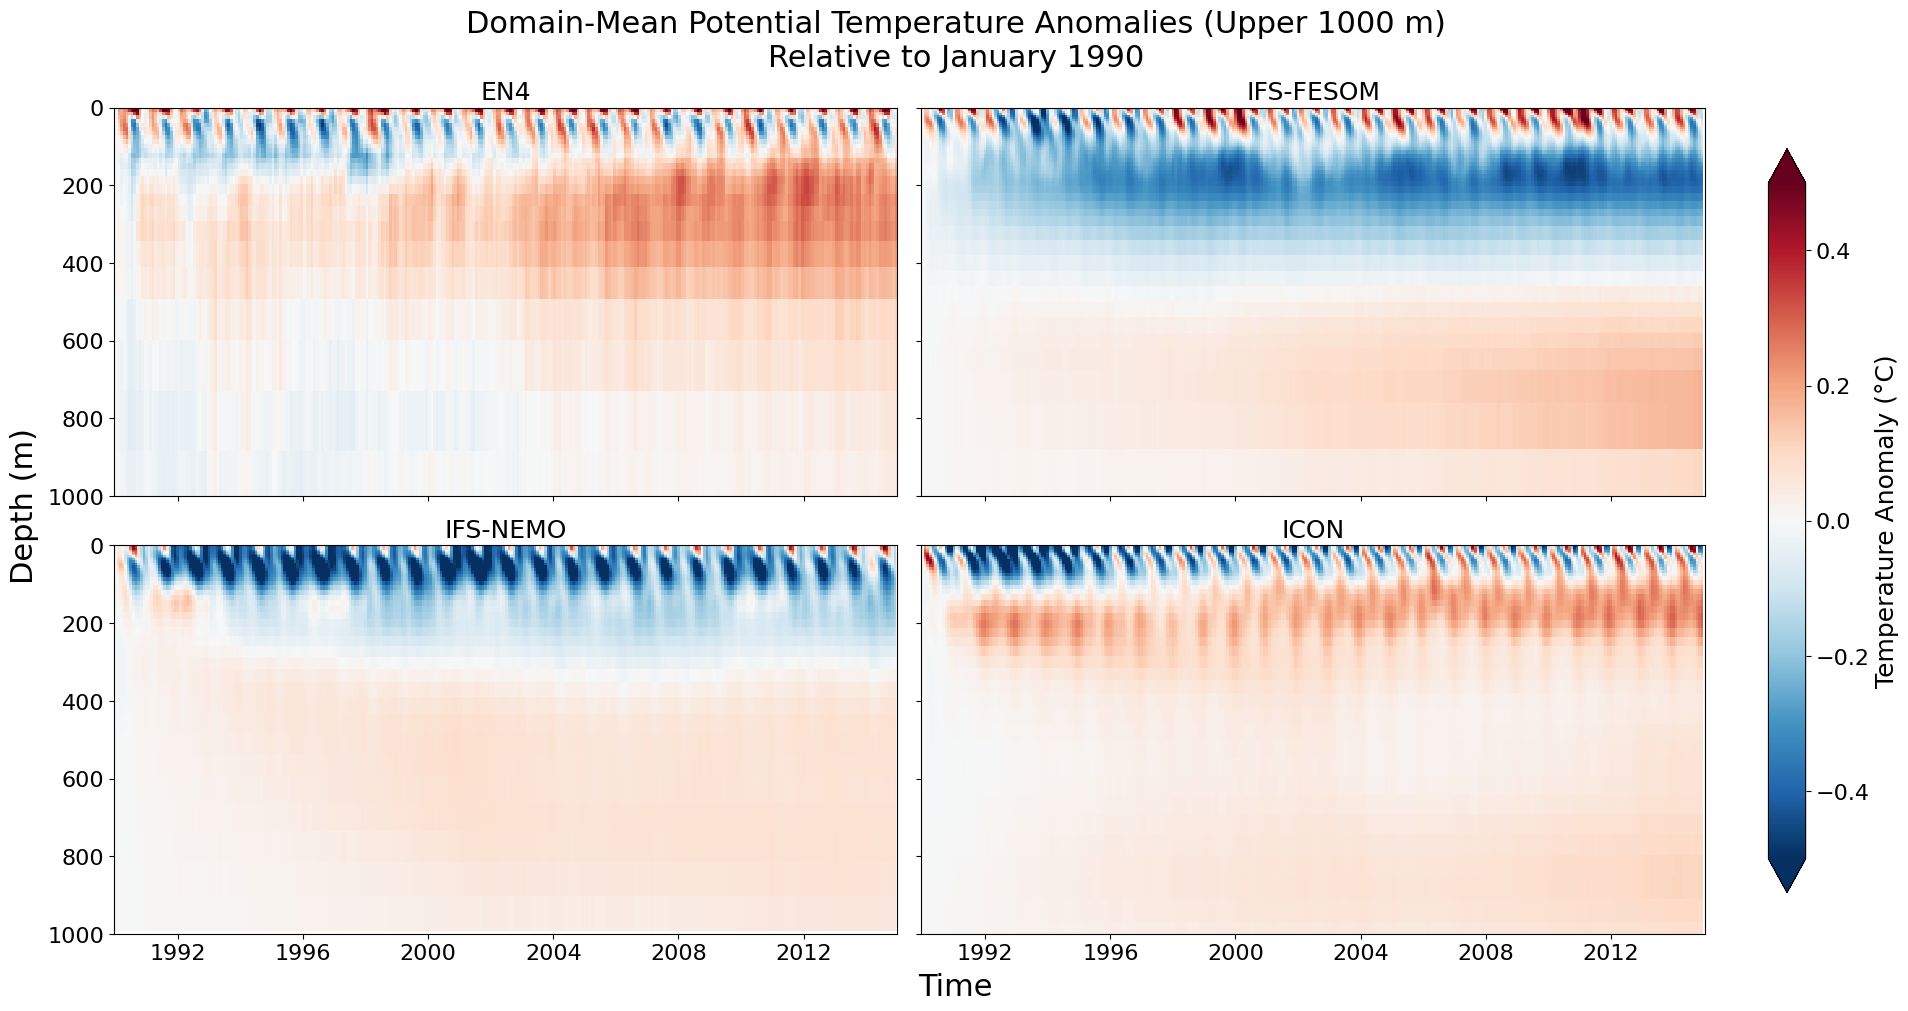

In [24]:
import matplotlib.pyplot as plt
import xarray as xr

# ... [Your data loading code remains the same] ...

fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)
axes = axes.flatten()

# Plot order: EN4, IFS-FESOM, IFS-NEMO, ICON
plot_order = ["EN4", "IFS-FESOM", "IFS-NEMO", "ICON"]

# Loop through axes and models
for ax, model in zip(axes, plot_order):
    da = thetao[model]

    # Convert to °C
    da_c = da - 273.15

    # Reference: first timestep (Jan 1990)
    ref = da_c.sel(time=da_c.time[0])
    
    # Anomaly
    anom = da_c - ref

    # Upper 1000 m and sort
    anom_1000 = anom.sel(depth=slice(0, 1000))
    anom_1000 = anom_1000.sortby("depth")

    # pcolormesh
    pcm = ax.pcolormesh(
        anom_1000["time"],
        anom_1000["depth"],
        anom_1000.T,
        shading="auto",
        cmap="RdBu_r",
        vmin=-0.5,
        vmax=0.5
    )

    ax.set_title(model, fontsize=18)
    ax.tick_params(labelsize=16)
    
    # FORCE Y-AXIS DIRECTION
    # Since sharey=True, we set specific limits (bottom, top)
    # This ensures 1000 is at the bottom and 0 is at the top
    ax.set_ylim(1000, 0)

# REMOVED: axes[3].axis("off") 
# (You have 4 models in plot_order, so you need the 4th panel active)

# Big common labels
fig.supxlabel("Time", fontsize=22)
fig.supylabel("Depth (m)", fontsize=22)

# Colorbar
# Attached to 'axes' (all panels) to center it properly
cbar = fig.colorbar(
    pcm,
    ax=axes, 
    orientation="vertical",
    extend="both",
    shrink=0.9,
    pad=0.04
)
cbar.set_label("Temperature Anomaly (°C)", fontsize=18)
cbar.ax.tick_params(labelsize=16)

fig.suptitle(
    "Domain-Mean Potential Temperature Anomalies (Upper 1000 m)\n"
    "Relative to January 1990",
    fontsize=22
)

plt.show()

# Error

In [2]:
import xarray as xr

path = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/thetao_o00i_r100_monthly_1990.nc"

ds = xr.open_dataset(path)

print(ds)

<xarray.Dataset>
Dimensions:    (time: 12, level: 69, lat: 180, lon: 360)
Coordinates:
  * level      (level) float64 2.5 7.5 12.5 ... 5.525e+03 5.825e+03 6.175e+03
    idx_level  (level) int64 ...
  * time       (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat        (lat) float64 -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon        (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
Data variables:
    thetao     (time, level, lat, lon) float64 ...


In [2]:
import xarray as xr
clim_temp = xr.open_dataset(f'{FESOM_DATA_ROOT}/climatology_EN4_1985/ng5/temp_healpix_128_7.nc')
print(clim_temp)

<xarray.Dataset>
Dimensions:  (depth: 69, ncells: 196608, lon: 196608, lat: 196608)
Coordinates:
  * depth    (depth) float64 2.5 7.5 12.5 17.5 ... 5.525e+03 5.825e+03 6.175e+03
  * lon      (lon) float64 45.0 45.35 44.65 45.0 ... 315.0 315.4 314.6 315.0
  * lat      (lat) float64 0.2984 0.5968 0.5968 ... -0.5968 -0.5968 -0.2984
Dimensions without coordinates: ncells
Data variables:
    temp     (depth, ncells) float64 ...
Attributes:
    climatology:    EN4_1985
    zoom:           7
    nside:          128
    original_mesh:  NG5


In [3]:
import xarray as xr
from pathlib import Path

file = Path(f"{EN4_DIR}/extracted/EN.4.2.2.f.analysis.g10.200408.nc")

# File size
size_mb = file.stat().st_size / 1024**2
print(f"File size: {size_mb:.2f} MB")

# Open dataset
ds = xr.open_dataset(file)

print(ds)

File size: 25.21 MB
<xarray.Dataset>
Dimensions:                          (depth: 42, lat: 173, lon: 360, time: 1,
                                      bnds: 2)
Coordinates:
  * depth                            (depth) float32 5.022 15.08 ... 5.35e+03
  * lat                              (lat) float32 -83.0 -82.0 ... 88.0 89.0
  * lon                              (lon) float32 1.0 2.0 3.0 ... 359.0 360.0
  * time                             (time) datetime64[ns] 2004-08-16T12:00:00
Dimensions without coordinates: bnds
Data variables:
    temperature                      (time, depth, lat, lon) float32 ...
    salinity                         (time, depth, lat, lon) float32 ...
    temperature_uncertainty          (time, depth, lat, lon) float32 ...
    salinity_uncertainty             (time, depth, lat, lon) float32 ...
    temperature_observation_weights  (time, depth, lat, lon) float32 ...
    salinity_observation_weights     (time, depth, lat, lon) float32 ...
    time_bnds        